## 03: Modeling
Objective: build baselines, compare models with cross-validation on the training set, and evaluate the final model once on the test set.

### 1. Load Processed Data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA_DIR = Path("../data/processed")

In [2]:
X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv")["Survived"]
y_test = pd.read_csv(DATA_DIR / "y_test.csv")["Survived"]

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train survival rate:", round(y_train.mean() * 100, 1), "%")

Train: (712, 19) | Test: (179, 19)
Train survival rate: 38.3 %


### 2. Baselines

In [3]:
# Baseline 1: always predict "did not survive"
majority_pred = np.zeros(len(y_train), dtype=int)

# Baseline 2: simple rule - females survive, males do not
sex_rule_pred = X_train["Sex_female"].to_numpy()

baselines = pd.DataFrame({
    "accuracy": [(majority_pred == y_train).mean(), (sex_rule_pred == y_train).mean()],
    "f1": [f1_score(y_train, majority_pred, zero_division=0), f1_score(y_train, sex_rule_pred)],
}, index=["Always 'did not survive'", "Sex rule (female = survive)"]).round(3)

baselines

,accuracy,f1
Always 'did not survive',0.617,0.000
Sex rule (female = survive),0.789,0.715


## 3. Model Comparison with 5-Fold Cross-Validation

##### [Model builder]

In [4]:
def build_models(columns):
    """Return the three models. Logistic Regression scales the continuous
    columns inside a Pipeline, so the scaler is fitted only on each training fold."""
    scale_cols = [c for c in ["Age", "FamilySize", "Fare_log"] if c in columns]
    prep = ColumnTransformer([("scale", StandardScaler(), scale_cols)],
                             remainder="passthrough")
    return {
        "Logistic Regression": Pipeline([
            ("prep", prep),
            ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
        ]),
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
        "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    }

#### [CV function]

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc"}


def evaluate(X, y):
    rows = {}
    for name, model in build_models(X.columns).items():
        res = cross_validate(model, X, y, cv=cv, scoring=scoring)
        rows[name] = {
            "accuracy_mean": res["test_accuracy"].mean(),
            "accuracy_std": res["test_accuracy"].std(),
            "f1_mean": res["test_f1"].mean(),
            "roc_auc_mean": res["test_roc_auc"].mean(),
        }
    return pd.DataFrame(rows).T.round(3)

#### [Run ar table]

In [6]:
cv_results = evaluate(X_train, y_train)
cv_results

,accuracy_mean,accuracy_std,f1_mean,roc_auc_mean
Logistic Regression,0.827,0.024,0.773,0.878
Random Forest,0.819,0.023,0.759,0.874
Gradient Boosting,0.820,0.029,0.755,0.894


##### [Chart (baseline-er sathe)]

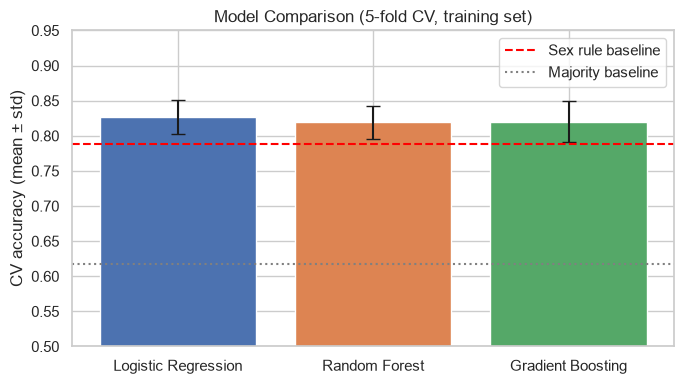

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(cv_results.index, cv_results["accuracy_mean"],
       yerr=cv_results["accuracy_std"], capsize=5,
       color=sns.color_palette()[:3])
ax.axhline(baselines.loc["Sex rule (female = survive)", "accuracy"],
           color="red", linestyle="--", label="Sex rule baseline")
ax.axhline(baselines.loc["Always 'did not survive'", "accuracy"],
           color="gray", linestyle=":", label="Majority baseline")
ax.set_ylim(0.5, 0.95)
ax.set_ylabel("CV accuracy (mean ± std)")
ax.set_title("Model Comparison (5-fold CV, training set)")
ax.legend()
plt.tight_layout()
plt.show()

#### A simple Sex rule already gives about 79% accuracy. My three models reach about 82-83% in cross-validation, so they beat the baseline, but the gap between the models is smaller than the fold-to-fold variation. So I treat them as roughly equal and choose using other criteria, like ROC-AUC, simplicity, and tuning.

## 4. Feature Set Comparison
#### [Ablation run]

In [8]:
FAMILY_COLS = {
    "FamilySize": ["FamilySize"],
    "IsAlone": ["IsAlone"],
    "FamilyGroup": ["FamilyGroup_Alone", "FamilyGroup_Small", "FamilyGroup_Large"],
}

family_variants = {
    "all three": ["FamilySize", "IsAlone", "FamilyGroup"],
    "FamilySize only": ["FamilySize"],
    "IsAlone only": ["IsAlone"],
    "FamilyGroup only": ["FamilyGroup"],
    "no family features": [],
}

rows = []
for variant, keep in family_variants.items():
    for use_cabin in [True, False]:
        drop = [c for key, cols in FAMILY_COLS.items() if key not in keep for c in cols]
        if not use_cabin:
            drop.append("has_cabin")
        res = evaluate(X_train.drop(columns=drop), y_train)
        for model_name, r in res.iterrows():
            rows.append({
                "family": variant,
                "has_cabin": use_cabin,
                "model": model_name,
                "accuracy": r["accuracy_mean"],
                "roc_auc": r["roc_auc_mean"],
            })

ablation = pd.DataFrame(rows)
print("Done:", len(ablation), "results")

Done: 30 results


### [Accuracy table]

In [9]:
acc_table = ablation.pivot_table(index=["family", "has_cabin"], columns="model", values="accuracy")
acc_table["mean"] = acc_table.mean(axis=1)
acc_table.sort_values("mean", ascending=False).round(3)

,model,Gradient Boosting,Logistic Regression,Random Forest,mean
family,has_cabin,,,,
FamilyGroup only,True,0.833,0.826,0.822,0.827
FamilySize only,True,0.824,0.829,0.819,0.824
all three,True,0.820,0.827,0.819,0.822
no family features,True,0.827,0.816,0.808,0.817
FamilyGroup only,False,0.815,0.826,0.808,0.816
IsAlone only,True,0.823,0.813,0.813,0.816
all three,False,0.816,0.822,0.796,0.811
FamilySize only,False,0.813,0.819,0.798,0.810
IsAlone only,False,0.826,0.809,0.794,0.810


#### [ROC-AUC table]

In [10]:
auc_table = ablation.pivot_table(index=["family", "has_cabin"], columns="model", values="roc_auc")
auc_table["mean"] = auc_table.mean(axis=1)
auc_table.sort_values("mean", ascending=False).round(3)

,model,Gradient Boosting,Logistic Regression,Random Forest,mean
family,has_cabin,,,,
FamilyGroup only,True,0.891,0.880,0.875,0.882
FamilySize only,True,0.894,0.877,0.875,0.882
all three,True,0.894,0.878,0.874,0.882
FamilyGroup only,False,0.889,0.876,0.868,0.878
IsAlone only,True,0.889,0.870,0.874,0.878
all three,False,0.888,0.874,0.869,0.877
FamilySize only,False,0.889,0.873,0.868,0.877
no family features,True,0.889,0.867,0.871,0.876
IsAlone only,False,0.888,0.866,0.868,0.874


#### I compared feature sets with cross-validation on the training set only. The differences were small, within the noise, so I kept the simplest reasonable set: FamilySize and has_cabin. I did not use the test set for this decision.

## 5. Hyperparameter Tuning
#### [Final feature set]

In [11]:
DROP_FINAL = ["IsAlone", "FamilyGroup_Alone", "FamilyGroup_Small", "FamilyGroup_Large"]
X_tr = X_train.drop(columns=DROP_FINAL)
X_te = X_test.drop(columns=DROP_FINAL)

print(X_tr.shape, X_te.shape)
print(list(X_tr.columns))

(712, 15) (179, 15)
['Pclass', 'Age', 'FamilySize', 'has_cabin', 'Fare_log', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']


#### [Grid search (3 model, ROC-AUC diye select)]

In [12]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "Random Forest": {"max_depth": [3, 5, 7, None], "min_samples_leaf": [1, 3, 5]},
    "Gradient Boosting": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1],
                          "max_depth": [2, 3]},
}

tuned = {}
for name, model in build_models(X_tr.columns).items():
    gs = GridSearchCV(model, param_grids[name], cv=cv,
                      scoring={"roc_auc": "roc_auc", "accuracy": "accuracy"},
                      refit="roc_auc")
    gs.fit(X_tr, y_train)
    tuned[name] = gs
    print(name, "->", gs.best_params_)

Logistic Regression -> {'model__C': 1}
Random Forest -> {'max_depth': None, 'min_samples_leaf': 3}
Gradient Boosting -> {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200}


#### [Default vs tuned table]

In [13]:
default_res = evaluate(X_tr, y_train)

rows = {}
for name, gs in tuned.items():
    i = gs.best_index_
    r = gs.cv_results_
    rows[name] = {
        "default_auc": default_res.loc[name, "roc_auc_mean"],
        "tuned_auc": r["mean_test_roc_auc"][i],
        "auc_std": r["std_test_roc_auc"][i],
        "default_acc": default_res.loc[name, "accuracy_mean"],
        "tuned_acc": r["mean_test_accuracy"][i],
        "acc_std": r["std_test_accuracy"][i],
    }

tuning_table = pd.DataFrame(rows).T.round(3)
tuning_table

,default_auc,tuned_auc,auc_std,default_acc,tuned_acc,acc_std
Logistic Regression,0.877,0.877,0.022,0.829,0.829,0.026
Random Forest,0.875,0.885,0.023,0.819,0.824,0.020
Gradient Boosting,0.894,0.896,0.013,0.824,0.823,0.016


#### [Final model]

In [14]:
best_auc_name = tuning_table["tuned_auc"].idxmax()
lr_auc = tuning_table.loc["Logistic Regression", "tuned_auc"]
gap = tuning_table.loc[best_auc_name, "tuned_auc"] - lr_auc
lr_std = tuning_table.loc["Logistic Regression", "auc_std"]

print(f"Best by ROC-AUC: {best_auc_name}")
print(f"Gap to Logistic Regression: {gap:.3f} | LR fold std: {lr_std:.3f}")

final_name = "Logistic Regression" if gap < lr_std else best_auc_name
print("Final model:", final_name)

Best by ROC-AUC: Gradient Boosting
Gap to Logistic Regression: 0.019 | LR fold std: 0.022
Final model: Logistic Regression


## 6. Final Evaluation on the Test Set
#### [Test set-e prediction metrics]

In [15]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             roc_auc_score, classification_report)

final_model = tuned[final_name].best_estimator_
y_pred = final_model.predict(X_te)
y_proba = final_model.predict_proba(X_te)[:, 1]


def summarize(y_true, pred, proba=None):
    return {
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "f1": f1_score(y_true, pred),
        "roc_auc": roc_auc_score(y_true, proba) if proba is not None else np.nan,
    }


sex_rule_test = X_test["Sex_female"].to_numpy()
majority_test = np.zeros(len(y_test), dtype=int)

test_results = pd.DataFrame({
    f"{final_name} (tuned)": summarize(y_test, y_pred, y_proba),
    "Sex rule": summarize(y_test, sex_rule_test),
    "Always 'did not survive'": summarize(y_test, majority_test),
}).T.round(3)

display(test_results)
print(classification_report(y_test, y_pred, target_names=["Did not survive", "Survived"]))

,accuracy,precision,recall,f1,roc_auc
Logistic Regression (tuned),0.838,0.786,0.797,0.791,0.867
Sex rule,0.777,0.738,0.652,0.692,NaN
Always 'did not survive',0.615,0.000,0.000,0.000,NaN


                 precision    recall  f1-score   support

Did not survive       0.87      0.86      0.87       110
       Survived       0.79      0.80      0.79        69

       accuracy                           0.84       179
      macro avg       0.83      0.83      0.83       179
   weighted avg       0.84      0.84      0.84       179



### [Confusion matrix & ROC curve]

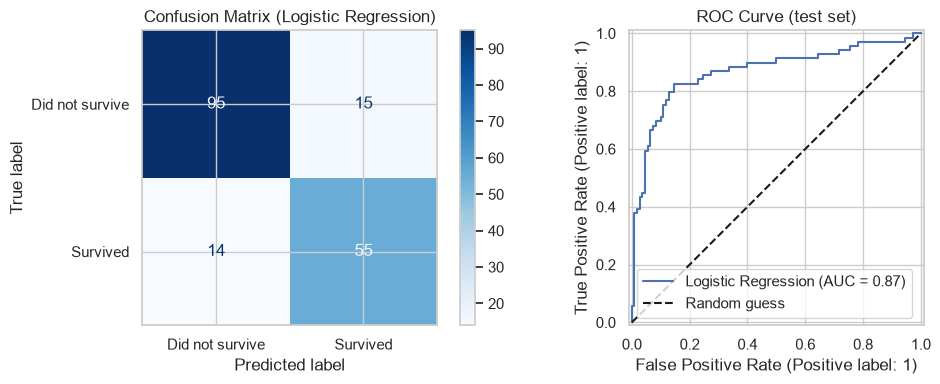

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Did not survive", "Survived"],
    cmap="Blues", ax=axes[0])
axes[0].set_title(f"Confusion Matrix ({final_name})")
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], name=final_name)
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].legend()
axes[1].set_title("ROC Curve (test set)")
plt.tight_layout()
plt.show()

#### [Test accuracy-r uncertainty (bootstrap)]

In [17]:
rng = np.random.default_rng(RANDOM_STATE)
y_true_arr = y_test.to_numpy()
boot = []
for _ in range(2000):
    idx = rng.integers(0, len(y_true_arr), len(y_true_arr))
    boot.append((y_pred[idx] == y_true_arr[idx]).mean())

low, high = np.percentile(boot, [2.5, 97.5])
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"95% bootstrap interval: {low:.3f} to {high:.3f}  (n = {len(y_test)})")

Test accuracy: 0.838
95% bootstrap interval: 0.782 to 0.888  (n = 179)


##### I chose the final model with cross-validation on the training set only, using a rule I fixed before tuning: if the best model is not clearly better than Logistic Regression, I keep Logistic Regression. On the test set it reached 83.8% accuracy and 0.867 ROC-AUC, compared with 77.7% for the simple Sex rule. The test set is small, so the accuracy interval is wide, about 78% to 89%.

## 7. Model Interpretation
### 7a. Logistic Regression Coefficients

##### [Coefficient ar odds ratio]

,coef,odds_ratio
Title_Mr,-1.223,0.294
Sex_male,-0.799,0.450
FamilySize,-0.720,0.487
Pclass,-0.551,0.576
Age,-0.473,0.623
Title_Rare,-0.313,0.731
Embarked_S,-0.249,0.779
Title_Miss,-0.229,0.795
Embarked_C,0.024,1.024
Embarked_Q,0.291,1.338


Sex effect (female - male coefficient): 1.664


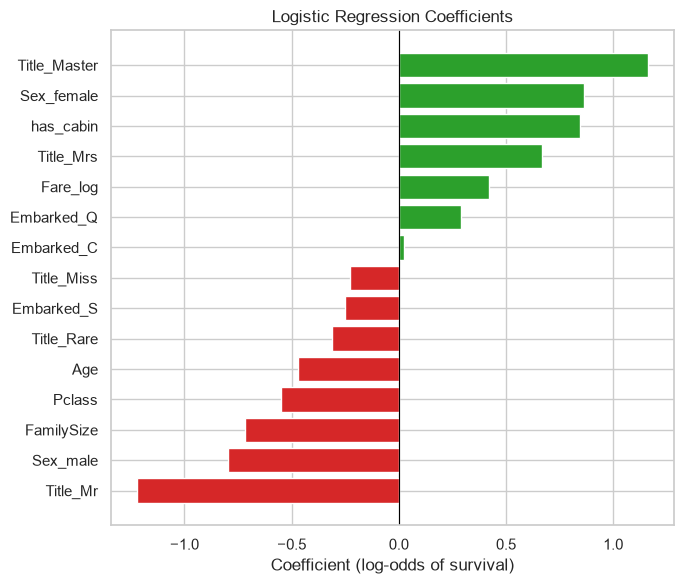

In [18]:
assert final_name == "Logistic Regression"

prep = final_model.named_steps["prep"]
lr = final_model.named_steps["model"]
feature_names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]

coef = pd.Series(lr.coef_[0], index=feature_names)
odds = pd.DataFrame({"coef": coef, "odds_ratio": np.exp(coef)}).sort_values("coef")
display(odds.round(3))

print("Sex effect (female - male coefficient):",
      round(coef["Sex_female"] - coef["Sex_male"], 3))

fig, ax = plt.subplots(figsize=(7, 6))
colors = ["tab:red" if c < 0 else "tab:green" for c in odds["coef"]]
ax.barh(odds.index, odds["coef"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coefficient (log-odds of survival)")
ax.set_title("Logistic Regression Coefficients")
plt.tight_layout()
plt.show()

### 7b. Permutation Importance (grouped) 
##### [Feature group shuffle korle AUC koto kome]

,auc_drop_mean,auc_drop_std
feature_group,,
Embarked,-0.003,0.005
Fare_log,0.008,0.008
has_cabin,0.011,0.007
Age,0.021,0.009
Pclass,0.026,0.010
FamilySize,0.051,0.014
Title,0.082,0.017
Sex,0.089,0.016


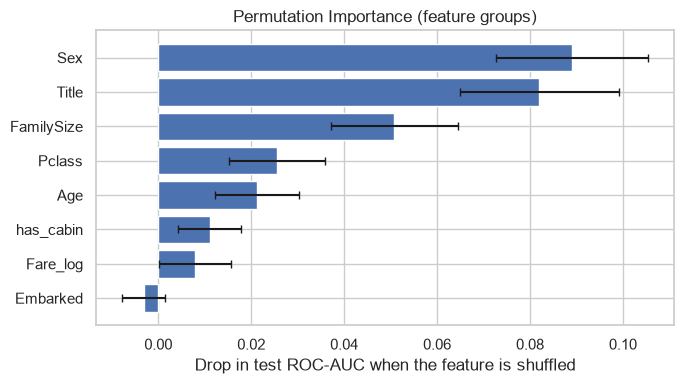

In [19]:
groups = {
    "Sex": ["Sex_female", "Sex_male"],
    "Title": [c for c in X_te.columns if c.startswith("Title_")],
    "Embarked": [c for c in X_te.columns if c.startswith("Embarked_")],
    "Pclass": ["Pclass"],
    "Age": ["Age"],
    "FamilySize": ["FamilySize"],
    "has_cabin": ["has_cabin"],
    "Fare_log": ["Fare_log"],
}
assert sorted(c for cols in groups.values() for c in cols) == sorted(X_te.columns)

rng = np.random.default_rng(RANDOM_STATE)
base_auc = roc_auc_score(y_test, final_model.predict_proba(X_te)[:, 1])

rows = []
for group, cols in groups.items():
    drops = []
    for _ in range(30):
        X_perm = X_te.copy()
        order = rng.permutation(len(X_perm))
        X_perm[cols] = X_perm[cols].to_numpy()[order]
        drops.append(base_auc - roc_auc_score(y_test, final_model.predict_proba(X_perm)[:, 1]))
    rows.append({"feature_group": group,
                 "auc_drop_mean": np.mean(drops),
                 "auc_drop_std": np.std(drops)})

perm_table = pd.DataFrame(rows).set_index("feature_group").sort_values("auc_drop_mean")
display(perm_table.round(3))

plt.figure(figsize=(7, 4))
plt.barh(perm_table.index, perm_table["auc_drop_mean"], xerr=perm_table["auc_drop_std"], capsize=3)
plt.xlabel("Drop in test ROC-AUC when the feature is shuffled")
plt.title("Permutation Importance (feature groups)")
plt.tight_layout()
plt.show()

### 7c. Error Analysis
##### [Kon group-e model bhul kore]

In [20]:
err = X_te.copy()
err["Sex"] = np.where(err["Sex_female"] == 1, "female", "male")
title_cols = [c for c in err.columns if c.startswith("Title_")]
err["Title"] = err[title_cols].idxmax(axis=1).str.replace("Title_", "")
err["actual"] = y_test.to_numpy()
err["pred"] = y_pred
err["proba"] = y_proba.round(2)
err["correct"] = err["actual"] == err["pred"]

print("Accuracy by Sex and Pclass:")
display(err.groupby(["Sex", "Pclass"])["correct"].agg(accuracy="mean", passengers="count").round(2))

mistakes = err[~err["correct"]].copy()
mistakes["confidence"] = (mistakes["proba"] - 0.5).abs()
print(f"Total mistakes: {len(mistakes)} of {len(err)}")
display(mistakes.sort_values("confidence", ascending=False)
        [["Sex", "Pclass", "Title", "Age", "actual", "pred", "proba"]].head(10))

Accuracy by Sex and Pclass:


accuracy  passengers
Sex    Pclass                      
female 1           0.93          15
       2           0.94          18
       3           0.68          28
male   1           0.67          30
       2           0.88          16
       3           0.92          72

Total mistakes: 29 of 179


,Sex,Pclass,Title,Age,actual,pred,proba
99,male,3,Mr,25.0,1,0,0.04
92,male,2,Mr,62.0,1,0,0.05
41,female,1,Miss,2.0,0,1,0.95
150,male,3,Mr,27.0,1,0,0.08
139,male,3,Mr,30.0,1,0,0.08
112,male,3,Mr,27.0,1,0,0.08
28,male,3,Mr,29.0,1,0,0.10
2,male,3,Mr,22.0,1,0,0.12
53,male,2,Mr,30.0,1,0,0.15
145,male,1,Mr,60.0,1,0,0.21


##### The model’s strongest signals are sex and title, then family size, class and age. Women and young boys had higher odds, and men and large families lower odds. The model makes most mistakes on 1st-class men and 3rd-class women, because it has no Sex and Pclass interaction. That is a limitation, and an interaction feature or a tree model is the next step.

### 8. Check that src/ matches the notebook

In [22]:
import json
import sys
sys.path.insert(0, "../src")

from sklearn.model_selection import train_test_split
import preprocessing, predict  # restart the kernel if you edit these files later

raw = pd.read_csv("../data/titanic_data.csv")
_, raw_test = train_test_split(raw, test_size=0.2, stratify=raw["Survived"],
                               random_state=RANDOM_STATE)
raw_test_X = raw_test.drop(columns="Survived")

model_src, fill_src = predict.load_artifacts()

# 1) Fill values: src vs notebook 02
with open("../data/processed/fill_values.json") as f:
    fill_nb = json.load(f)
print("Fill values match:", fill_nb == fill_src)

# 2) Feature matrix: src vs notebook
X_src = preprocessing.build_features(raw_test_X, fill_src).reset_index(drop=True)
pd.testing.assert_frame_equal(X_src, X_te.reset_index(drop=True), check_dtype=False)
print("Feature matrix identical")

# 3) Predictions: src vs notebook
out = predict.predict_dataframe(raw_test_X)
print("Same y_test:", np.array_equal(raw_test["Survived"].to_numpy(), y_test.to_numpy()))
print("Same labels:", np.array_equal(out["prediction"].to_numpy(), y_pred))
print("Max probability difference:", np.abs(out["probability"].to_numpy() - y_proba).max())

Fill values match: True
Feature matrix identical
Same y_test: True
Same labels: True
Max probability difference: 1.2989609388114332e-14
